In [1]:
######## Projec the growth of WZ and VZ with rate ############
import os
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from rasterio.features import sieve
from rasterio.enums import Resampling
from scipy.ndimage import binary_dilation
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import pandas as pd
from rasterio.merge import merge
from rasterio.plot import show
import glob
import plotly.io as pio
import random

/Users/bz294/miniconda3/envs/whitezone/lib/python3.10/site-packages/rasterio/__init__.py:220: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix be returned.
  s = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)


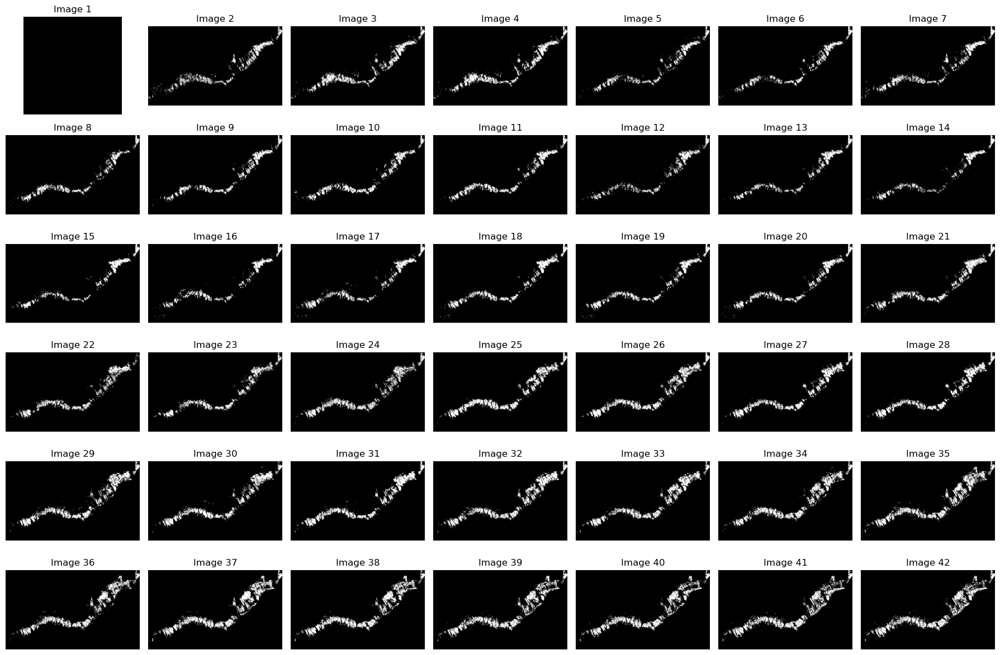

In [3]:
# === STEP 1: Set up ===
img_dir = "/Volumes/Malonelab/Research/Whitezone/Result/Emulation/Final/CDthreshold06/CD_closest_GE"  # <- Replace with your folder path
img_files = sorted([os.path.join(img_dir, f) for f in os.listdir(img_dir) if f.endswith('.tif')])

# === STEP 2: Read and mask each image (keep only value == 2) ===
masked_images = []
for file in img_files:
    with rasterio.open(file) as src:
        data = src.read(1)
        mask = (data == 2).astype(np.uint8)  # 1 where value == 2, else 0
        masked_images.append(mask)

# === STEP 3: Plot all 41 layers in a grid ===
n = len(masked_images)
cols = 7
rows = int(np.ceil(n / cols))

fig, axes = plt.subplots(rows, cols, figsize=(18, 12), facecolor='white')
axes = axes.flatten()

for i in range(n):
    ax = axes[i]
    ax.imshow(masked_images[i], cmap='gray', vmin=0, vmax=1)
    ax.set_title(f"Image {i+1}")
    ax.axis('off')

# Hide unused subplots
for j in range(n, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.savefig("value_eq_2_all_years.png", dpi=300, facecolor='white')
plt.show()

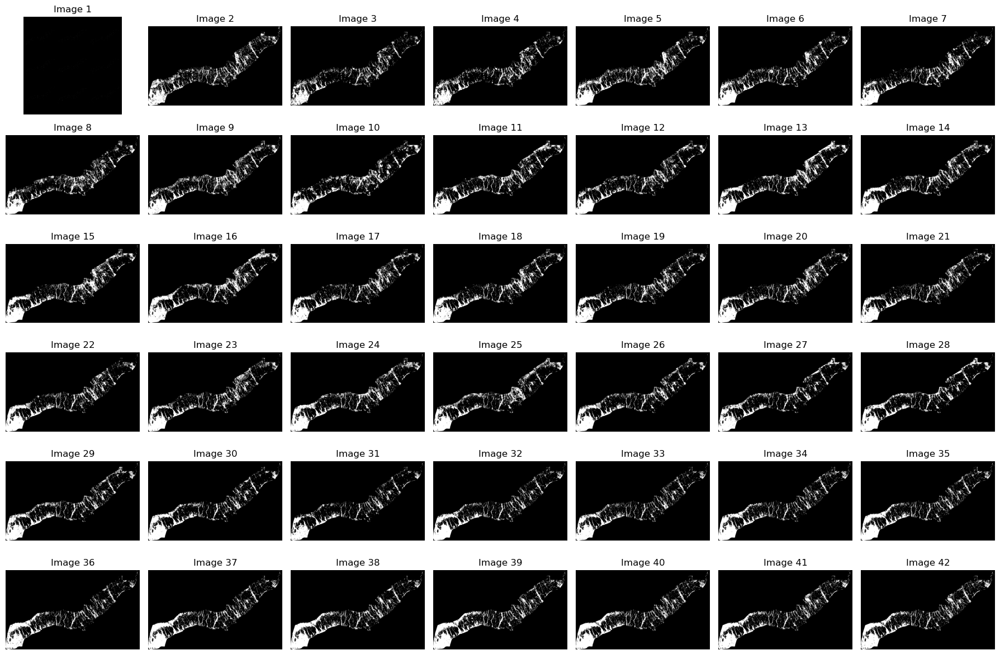

In [4]:
# === STEP 1: Set up ===
img_dir = "/Volumes/Malonelab/Research/Whitezone/Result/Emulation/Final/CDthreshold06/CD_closest_GE"  # <- Replace with your folder path
img_files = sorted([os.path.join(img_dir, f) for f in os.listdir(img_dir) if f.endswith('.tif')])

# === STEP 2: Read and mask each image (keep only value == 2) ===
masked_images = []
for file in img_files:
    with rasterio.open(file) as src:
        data = src.read(1)
        mask = (data == 1).astype(np.uint8)  # 1 where value == 2, else 0
        masked_images.append(mask)

# === STEP 3: Plot all 41 layers in a grid ===
n = len(masked_images)
cols = 7
rows = int(np.ceil(n / cols))

fig, axes = plt.subplots(rows, cols, figsize=(18, 12), facecolor='white')
axes = axes.flatten()

for i in range(n):
    ax = axes[i]
    ax.imshow(masked_images[i], cmap='gray', vmin=0, vmax=1)
    ax.set_title(f"Image {i+1}")
    ax.axis('off')

# Hide unused subplots
for j in range(n, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.savefig("value_eq_2_all_years.png", dpi=300, facecolor='white')
plt.show()

In [54]:
#### calculate the change rate for wz and vz ########
# === Step 1: Load first and last raster ===
#folder = "/Volumes/MaloneLab/Research/Whitezone/Result/Emulation/Final/CDthreshold06/CD_closest_GE/"  # <-- replace with your actual path
folder = "/Volumes/MaloneLab/Research/Whitezone/Result/Emulation/Final/CDthreshold06/CD_closest_GE/Subregion_new/Region_2"  # <-- replac
tif_files = sorted([f for f in os.listdir(folder) if f.endswith('.tif')])

# First and last year images
first_path = os.path.join(folder, tif_files[1])
last_path = os.path.join(folder, tif_files[-2])

# first_path = os.path.join(folder, tif_files[-12])
# last_path = os.path.join(folder, tif_files[-1])

with rasterio.open(first_path) as src:
    first_img = src.read(1)

with rasterio.open(last_path) as src:
    last_img = src.read(1)

# === Step 2: Count pixel changes for each class ===
for value in [0, 1, 2, 3]:
    count_first = np.sum(first_img == value)
    count_last = np.sum(last_img == value)
    diff = count_last - count_first
    rate_per_year = diff / 38
    print(f"Class {value} ({['Out','VZ','WZ','TZ'][value]}): "
          f"{count_first} → {count_last} (Δ={diff}, Rate: {rate_per_year:.2f} pixels/year)")


Class 0 (Out): 124557 → 124557 (Δ=0, Rate: 0.00 pixels/year)
Class 1 (VZ): 10911 → 14609 (Δ=3698, Rate: 97.32 pixels/year)
Class 2 (WZ): 17232 → 24762 (Δ=7530, Rate: 198.16 pixels/year)
Class 3 (TZ): 37200 → 25972 (Δ=-11228, Rate: -295.47 pixels/year)


In [44]:
tif_files[-12]

'raster_2013.tif'

In [45]:
tif_files[-1]

'raster_2024_cd.tif'

In [10]:
def simulate_expansion_with_mutual_conversion(
    raster_path,
    WZ_per_year,
    VZ_per_year,
    tz_conversion,
    mutual_conversion,
    years
):
    """
    Simulate WZ and VZ expansion over a number of years, mostly into TZ but allowing minor mutual conversion.

    Parameters:
        raster_path (str): Full path to the initial raster (.tif).
        WZ_per_year (int): Number of pixels WZ expands per year.
        VZ_per_year (int): Number of pixels VZ expands per year.
        tz_conversion (int): Portion of expansion toward TZ (numerator in ratio).
        mutual_conversion (int): Portion of expansion toward the other vegetation class (numerator in ratio).
        years (int): Number of years to simulate.

    Returns:
        np.ndarray: The landcover array after simulation.
    """

    # === Load base raster ===
    with rasterio.open(raster_path) as src:
        base = src.read(1)
        profile = src.profile

    landcover = base.copy()

    for year in range(years):
        WZ_mask = (landcover == 2)
        VZ_mask = (landcover == 1)
        TZ_mask = (landcover == 3)

        # === WZ expansion ===
        if WZ_per_year > 0:
            total_ratio = tz_conversion + mutual_conversion
            WZ_to_TZ = int(WZ_per_year * tz_conversion / total_ratio)
            WZ_to_VZ = WZ_per_year - WZ_to_TZ

            WZ_edge_TZ = binary_dilation(WZ_mask) & TZ_mask
            WZ_edge_VZ = binary_dilation(WZ_mask) & VZ_mask

            # Avoid overlap between WZ and VZ expansion into the same TZ cells
            VZ_edge_TZ = binary_dilation(VZ_mask) & TZ_mask
            WZ_edge_TZ[VZ_edge_TZ] = False

            wz_tz_candidates = list(zip(*np.where(WZ_edge_TZ)))
            wz_vz_candidates = list(zip(*np.where(WZ_edge_VZ)))

            wz_new_TZ = random.sample(wz_tz_candidates, min(WZ_to_TZ, len(wz_tz_candidates)))
            wz_new_VZ = random.sample(wz_vz_candidates, min(WZ_to_VZ, len(wz_vz_candidates)))

            for r, c in wz_new_TZ:
                landcover[r, c] = 2  # WZ expands into TZ
            for r, c in wz_new_VZ:
                landcover[r, c] = 2  # WZ converts VZ

        else:
            wz_new_TZ = wz_new_VZ = []  # For print statement

        # === VZ expansion or retraction ===
        if VZ_per_year >= 0:
            total_ratio = tz_conversion + mutual_conversion
            VZ_to_TZ = int(VZ_per_year * tz_conversion / total_ratio)
            VZ_to_WZ = VZ_per_year - VZ_to_TZ

            VZ_edge_TZ = binary_dilation(VZ_mask) & TZ_mask
            VZ_edge_WZ = binary_dilation(VZ_mask) & WZ_mask

            vz_tz_candidates = list(zip(*np.where(VZ_edge_TZ)))
            vz_wz_candidates = list(zip(*np.where(VZ_edge_WZ)))

            vz_new_TZ = random.sample(vz_tz_candidates, min(VZ_to_TZ, len(vz_tz_candidates)))
            vz_new_WZ = random.sample(vz_wz_candidates, min(VZ_to_WZ, len(vz_wz_candidates)))

            for r, c in vz_new_TZ:
                landcover[r, c] = 1  # VZ expands into TZ
            for r, c in vz_new_WZ:
                landcover[r, c] = 1  # VZ converts WZ

        else:
            # === VZ retraction into TZ ===
            num_retract = abs(VZ_per_year)
            # VZ pixels touching non-VZ are edge pixels
            edge_mask = binary_dilation(VZ_mask) & (~VZ_mask)
            VZ_edge = VZ_mask & edge_mask

            VZ_edge_coords = list(zip(*np.where(VZ_edge)))
            retract_coords = random.sample(VZ_edge_coords, min(num_retract, len(VZ_edge_coords)))

            for r, c in retract_coords:
                landcover[r, c] = 3  # VZ retracts to TZ

            vz_new_TZ = retract_coords
            vz_new_WZ = []  # No WZ conversion in retraction mode

        print(f"Year {year+1}/{years}: "
              f"WZ→TZ={len(wz_new_TZ)}, WZ→VZ={len(wz_new_VZ)} | "
              f"VZ→TZ={len(vz_new_TZ)}, VZ→WZ={len(vz_new_WZ)}")

    return landcover


In [57]:
r1 = 82985
r2 = 54928
r3 = 65310

op_rg2_wz = int(np.round(65 / r1 * r2))
op_rg3_wz = int(np.round(65 / r1 * r3))
print(op_rg2_wz)
print(op_rg3_wz)

op_rg2_vz = int(np.round(352 / r1 * r2))
op_rg3_vz = int(np.round(352 / r1 * r3))
print(op_rg2_vz)
print(op_rg3_vz)


# pes_rg1 = int(np.round(-35 * r1 / r2))
# print(pes_rg1)

43
51
233
277


In [58]:
r1 = 82985
r2 = 54928
r3 = 65310


pes_rg_vz = int(np.round(103 * r1 / r3))
pes_rg_wz = int(np.round(191 * r1 / r3))
print(pes_rg_vz)
print(pes_rg_wz)

131
243


In [59]:
### Rate (pixel/yr) ##

## Region_0: WZ_per_year = 193  # pixels/year, VZ_per_year = 253  # pixels/year ## Ratio: 128 : 2
## Region_1: WZ_per_year = 198  # pixels/year, VZ_per_year = 33  # pixels/year  ## Ratio: 166 : 5
## Region_1: WZ_per_year = 228  # pixels/year, VZ_per_year = 131  # pixels/year ## Ratio: 256: 7

regions = [
    {
        "name": "Region_0",
        "WZ_per_year": 65,
        "VZ_per_year": 352,
        "tz_conversion": 19,
        "mutual_conversion": 2
    },
    {
        "name": "Region_1",
        "WZ_per_year": 160,
        "VZ_per_year": -30,
        "tz_conversion": 9,
        "mutual_conversion": 1
    },
    {
        "name": "Region_2",
        "WZ_per_year": 191,
        "VZ_per_year": 103,
        "tz_conversion": 17,
        "mutual_conversion": 2
    }
]

optimistic_regions = [
    {
        "name": "Region_0",
        "WZ_per_year": 65,
        "VZ_per_year": 352,
        "tz_conversion": 19,
        "mutual_conversion": 2
    },
    {
        "name": "Region_1",
        "WZ_per_year": 43,
        "VZ_per_year": 233,
        "tz_conversion": 9,
        "mutual_conversion": 1
    },
    {
        "name": "Region_2",
        "WZ_per_year": 51,
        "VZ_per_year": 277,
        "tz_conversion": 17,
        "mutual_conversion": 2
    }
]

pessimistic_regions = [
    {
        "name": "Region_0",
        "WZ_per_year": 243,
        "VZ_per_year": 131,
        "tz_conversion": 19,
        "mutual_conversion": 2
    },
    {
        "name": "Region_1",
        "WZ_per_year": 160,
        "VZ_per_year": -30,
        "tz_conversion": 9,
        "mutual_conversion": 1
    },
    {
        "name": "Region_2",
        "WZ_per_year": 191,
        "VZ_per_year": 103,
        "tz_conversion": 17,
        "mutual_conversion": 2
    }
]

Year 1/50: WZ→TZ=170, WZ→VZ=21 | VZ→TZ=92, VZ→WZ=11
Year 2/50: WZ→TZ=170, WZ→VZ=21 | VZ→TZ=92, VZ→WZ=11
Year 3/50: WZ→TZ=170, WZ→VZ=21 | VZ→TZ=92, VZ→WZ=11
Year 4/50: WZ→TZ=170, WZ→VZ=21 | VZ→TZ=92, VZ→WZ=11
Year 5/50: WZ→TZ=170, WZ→VZ=21 | VZ→TZ=92, VZ→WZ=11
Year 6/50: WZ→TZ=170, WZ→VZ=21 | VZ→TZ=92, VZ→WZ=11
Year 7/50: WZ→TZ=170, WZ→VZ=21 | VZ→TZ=92, VZ→WZ=11
Year 8/50: WZ→TZ=170, WZ→VZ=21 | VZ→TZ=92, VZ→WZ=11
Year 9/50: WZ→TZ=170, WZ→VZ=21 | VZ→TZ=92, VZ→WZ=11
Year 10/50: WZ→TZ=170, WZ→VZ=21 | VZ→TZ=92, VZ→WZ=11
Year 11/50: WZ→TZ=170, WZ→VZ=21 | VZ→TZ=92, VZ→WZ=11
Year 12/50: WZ→TZ=170, WZ→VZ=21 | VZ→TZ=92, VZ→WZ=11
Year 13/50: WZ→TZ=170, WZ→VZ=21 | VZ→TZ=92, VZ→WZ=11
Year 14/50: WZ→TZ=170, WZ→VZ=21 | VZ→TZ=92, VZ→WZ=11
Year 15/50: WZ→TZ=170, WZ→VZ=21 | VZ→TZ=92, VZ→WZ=11
Year 16/50: WZ→TZ=170, WZ→VZ=21 | VZ→TZ=92, VZ→WZ=11
Year 17/50: WZ→TZ=170, WZ→VZ=21 | VZ→TZ=92, VZ→WZ=11
Year 18/50: WZ→TZ=170, WZ→VZ=21 | VZ→TZ=92, VZ→WZ=11
Year 19/50: WZ→TZ=170, WZ→VZ=21 | VZ→TZ=92, VZ→WZ=11
Ye

/var/folders/yw/3l8t5xh50v33m6zjql7k1rzsvhfd38/T/ipykernel_5257/1204404619.py:43: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



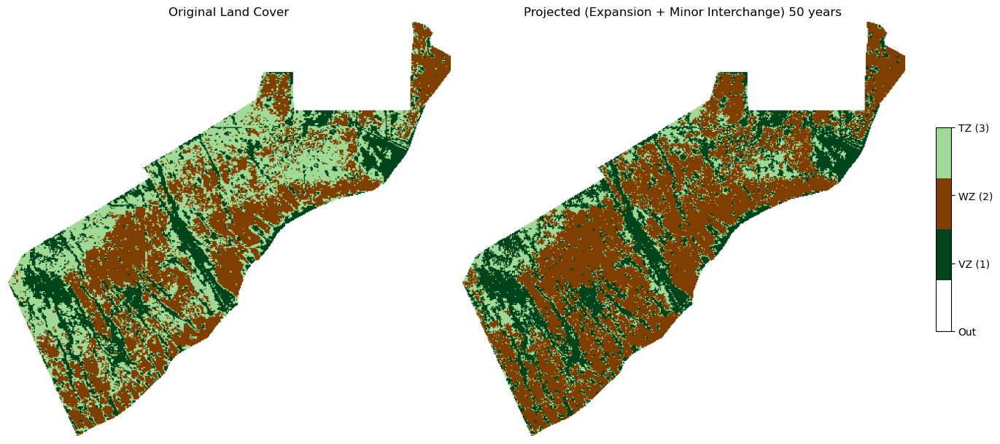

Change in number of pixels after 25 years:
VZ: 4100 pixels
WZ: 9000 pixels
TZ: -13100 pixels
Land cover transitions over 25 years (in pixels):
         To_VZ  To_WZ  To_TZ
From_VZ  14220    660      0
From_WZ    372  25455      0
From_TZ   4388   8712  11519


In [81]:
base_dir = "/Volumes/MaloneLab/Research/Whitezone/Result/Emulation/Final/CDthreshold06/CD_closest_GE/Subregion_new"
output_dir = "/Volumes/MaloneLab/Research/Whitezone/Result/Spatial_Modelling/Results/"
region = pessimistic_regions[2]  # Change to 0, 1 or 2 for Region_0, Region_1 or Region_2
year = 50


region_dir = os.path.join(base_dir, region["name"])
tif_files = sorted([f for f in os.listdir(region_dir) if f.endswith('.tif')])
initial_raster = os.path.join(region_dir, tif_files[-1])  # use the last timestep

with rasterio.open(initial_raster) as src:
    base = src.read(1)
    profile = src.profile

final_landcover = simulate_expansion_with_mutual_conversion(
        raster_path=initial_raster,
        WZ_per_year=region["WZ_per_year"],
        VZ_per_year=region["VZ_per_year"],
        tz_conversion=region["tz_conversion"],
        mutual_conversion=region["mutual_conversion"],
        years=year
    )
# === Optional: Plot results ===
# === Step 4: Plot ===
cmap = ListedColormap(['white', '#00441b', '#7f3f00', '#a1d996'])  # 0=white, 1=VZ, 2=WZ, 3=TZ

fig, axs = plt.subplots(1, 2, figsize=(14, 7))

axs[0].imshow(base, cmap=cmap, vmin=0, vmax=3)
axs[0].set_title("Original Land Cover")
axs[0].axis("off")

axs[1].imshow(final_landcover, cmap=cmap, vmin=0, vmax=3)
axs[1].set_title("Projected (Expansion + Minor Interchange) " + str(year) + " years")
axs[1].axis("off")

cbar_ax = fig.add_axes([0.92, 0.3, 0.015, 0.4])
cbar = fig.colorbar(axs[1].images[0], cax=cbar_ax)
cbar.set_ticks([0, 1, 2, 3])
cbar.set_ticklabels(["Out", "VZ (1)", "WZ (2)", "TZ (3)"])
cbar.ax.tick_params(labelsize=10)

plt.tight_layout(rect=[0, 0, 0.9, 1])
plt.show()

# Open the original raster to get metadata
with rasterio.open(initial_raster) as src:
    meta = src.meta.copy()

# Update metadata for writing the output raster
meta.update({
    "dtype": 'uint8',  # or match your array dtype
    "count": 1,
    "compress": 'lzw'  # optional compression
})

# Define output path
output_tif = os.path.join(output_dir, region["name"] + f"_final_landcover_{year}yrs.tif")

# Write the final_landcover array to GeoTIFF
with rasterio.open(output_tif, 'w', **meta) as dst:
    dst.write(final_landcover.astype('uint8'), 1)  # 1 means first (and only) band
    
# === Compute Pixel-Wise Differences ===
# Count pixels in the original land cover
base_counts = {
    "VZ": np.sum(base == 1),
    "WZ": np.sum(base == 2),
    "TZ": np.sum(base == 3)
}

# Count pixels in the simulated land cover
final_counts = {
    "VZ": np.sum(final_landcover == 1),
    "WZ": np.sum(final_landcover == 2),
    "TZ": np.sum(final_landcover == 3)
}

# Compute differences
diff_counts = {
    "VZ": final_counts["VZ"] - base_counts["VZ"],
    "WZ": final_counts["WZ"] - base_counts["WZ"],
    "TZ": final_counts["TZ"] - base_counts["TZ"]
}

# Print results
print("Change in number of pixels after 25 years:")
for key in diff_counts:
    print(f"{key}: {diff_counts[key]} pixels")
    
    
####### inter exchange between land cover types #######
# Flatten the arrays
base_flat = base.flatten()
final_flat = final_landcover.flatten()

# Initialize transition matrix
transition_matrix = np.zeros((3, 3), dtype=int)

# Mapping: 1 = VZ, 2 = WZ, 3 = TZ
for i in range(1, 4):        # From class
    for j in range(1, 4):    # To class
        transition_matrix[i - 1, j - 1] = np.sum((base_flat == i) & (final_flat == j))

# Convert to DataFrame for clarity
df_transition = pd.DataFrame(
    transition_matrix,
    index=["From_VZ", "From_WZ", "From_TZ"],
    columns=["To_VZ", "To_WZ", "To_TZ"]
)

print("Land cover transitions over 25 years (in pixels):")
print(df_transition)


In [61]:
# === Count land cover pixels in the initial base map ===
initial_counts = {
    "VZ": np.sum(base == 1),
    "WZ": np.sum(base == 2),
    "TZ": np.sum(base == 3)
}

print("Initial land cover pixel counts:")
for key, val in initial_counts.items():
    print(f"{key}: {val} pixels")

Initial land cover pixel counts:
VZ: 16375 pixels
WZ: 26289 pixels
TZ: 26696 pixels


In [ ]:
# R1: 
# Change in number of pixels after 25 years:
# VZ: 8775 pixels
# WZ: 1475 pixels
# TZ: -10250 pixels

# Change in number of pixels after 50 years:
# VZ: 17550 pixels
# WZ: 2950 pixels
# TZ: -20500 pixels

# R2:
# Change in number of pixels after 25 years:
# VZ: -125 pixels
# WZ: 4150 pixels
# TZ: -4025 pixels

#Change in number of pixels after 50 years:
# VZ: -250 pixels
# WZ: 8300 pixels
# TZ: -8050 pixels

#R3:
# Change in number of pixels after 25 years:
# VZ: 2425 pixels
# WZ: 4700 pixels
# TZ: -7125 pixels

# Change in number of pixels after 25 years:
# VZ: 4850 pixels
# WZ: 9400 pixels
# TZ: -14250 pixels

## Inter exchange between land cover types ##
#R1
#      To_VZ  To_WZ  To_TZ
# From_VZ  42973     13      0
# From_WZ    256  16738      0
# From_TZ  17307   3193   2617

#R2
#  To_VZ  To_WZ  To_TZ
# From_VZ   9668    125      0
# From_WZ      0  13245      0
# From_TZ      0   4025  23734

# R3
#    To_VZ  To_WZ  To_TZ
# From_VZ  16248    127      0
# From_WZ     71  26218      0
# From_TZ   2481   4644  19571

In [95]:
#### Alluvial plot based on images #####

pio.renderers.default = 'notebook'

import os
import numpy as np
import rasterio
from collections import Counter
import plotly.graph_objects as go
import plotly.io as pio

pio.renderers.default = 'notebook'  # or 'browser' if notebook doesn't show

# --- Set raster directory (update if needed) ---
raster_dir = '/Volumes/MaloneLab/Research/Whitezone/Result/Emulation/Final/CDthreshold06/CD_closest_GE/Prediction/Pessimistic/'
raster_paths = sorted([os.path.join(raster_dir, f) for f in os.listdir(raster_dir) if f.endswith('.tif')])

# --- Define selected years ---
selected_years = [2024, 2049, 2074]

# --- Load raster data ---
stack = []
for path in raster_paths:
    with rasterio.open(path) as src:
        arr = src.read(1).astype(np.float32)
        arr[arr == 0] = np.nan  # assume 0 is nodata
        stack.append(arr)
stack = np.stack(stack, axis=0)

# --- Mask valid pixels and extract transitions ---
valid_mask = np.all(~np.isnan(stack), axis=0)
transitions = stack[:, valid_mask]
transition_strs = ["→".join(map(str, seq.astype(int))) for seq in transitions.T]
counts = Counter(transition_strs)

# --- Mapping and visual configuration ---
label_map = {'1': 'VZ', '2': 'WZ', '3': 'TZ'}  # class to label
fixed_order = ['3', '2', '1']  # TZ → WZ → VZ

label_names = []
for year in selected_years:
    for code in fixed_order:
        label_names.append(f"{label_map[code]} ({year})")

label_name_to_idx = {name: i for i, name in enumerate(label_names)}

# --- Sankey links ---
source = []
target = []
value = []

for k, v in counts.items():
    steps = k.split("→")
    # Ensure we have both 2049 and 2074 transitions present
    for i in range(len(steps) - 1):
        src_code = steps[i]
        tgt_code = steps[i + 1]

        # Skip transitions from VZ or WZ (codes '1' or '2') to TZ ('3') between the second and third years
        if i == 1 and src_code in {'1', '2'} and tgt_code == '3':
            continue

        if src_code in label_map and tgt_code in label_map:
            src_label = f"{label_map[src_code]} ({selected_years[i]})"
            tgt_label = f"{label_map[tgt_code]} ({selected_years[i+1]})"
            source.append(label_name_to_idx[src_label])
            target.append(label_name_to_idx[tgt_label])
            value.append(v)

# --- Node y positions ---
y_map = {'3': 0.0, '2': 0.5, '1': 1.0}
y_positions = []
for _ in selected_years:
    for code in fixed_order:
        y_positions.append(y_map[code])

# --- Node colors ---
color_map = {'1': '#00441b', '2': '#b08b5b', '3': '#a1d996'}  # VZ, WZ, TZ
node_colors = []
for _ in selected_years:
    for code in fixed_order:
        node_colors.append(color_map[code])

# --- Sankey plot ---
fig = go.Figure(go.Sankey(
    node=dict(
        label=[""] * len(label_names),
        pad=15,
        thickness=20,
        y=y_positions,
        color=node_colors
    ),
    link=dict(
        source=source,
        target=target,
        value=value,
        color='rgba(150, 150, 150, 0.3)'
    )
))

fig.update_layout(
    title_text="Land Cover Transitions (2024–2074)",
    font=dict(family="Times New Roman", size=16, color="black")
)

fig.show()


In [87]:
######## Mosaicing into one figure for 25 and 50 year scenario #####

# Folder containing the images
folder = "/Volumes/MaloneLab/Research/Whitezone/Result/Spatial_Modelling/Results/Business_as_usual/"

# Collect all .tif files with '25' in filename
tif_files = glob.glob(os.path.join(folder, "*50*.tif"))

# Open all rasters
src_files_to_mosaic = [rasterio.open(fp) for fp in tif_files]

# Merge
mosaic, out_transform = merge(src_files_to_mosaic)

# Prepare output metadata
out_meta = src_files_to_mosaic[0].meta.copy()
out_meta.update({
    "height": mosaic.shape[1],
    "width": mosaic.shape[2],
    "transform": out_transform,
    "compress": "lzw",
    "count": 1,  # Single-band for color map
    "dtype": "uint8"
})

# Output file path
output_mosaic_path = os.path.join(folder, "mosaic_50yrs_colored.tif")

# Define color map: 0 is background, 1-VZ, 2-WZ, 3-TZ
colormap = {
    0: (255, 255, 255, 255),   # white (background)
    1: (0, 68, 27, 255),       # #00441b → dark green
    2: (176, 139, 91, 255),      # #b08b5b → dark brown
    3: (161, 217, 150, 255),   # #a1d996 → light green
}

# Write to GeoTIFF with colormap
with rasterio.open(output_mosaic_path, "w", **out_meta) as dest:
    dest.write(mosaic[0].astype('uint8'), 1)  # Write first band
    dest.write_colormap(1, colormap)

print("Saved mosaic with color table:", output_mosaic_path)


Saved mosaic with color table: /Volumes/MaloneLab/Research/Whitezone/Result/Spatial_Modelling/Results/Business_as_usual/mosaic_50yrs_colored.tif


In [105]:
############### Calculate the rates in km2 for predictions ###################
#folder = '/Volumes/MaloneLab/Research/Whitezone/Result/Emulation/Final/CDthreshold06/CD_closest_GE/Prediction/BAU/'  # <-- replac
folder = '/Volumes/MaloneLab/Research/Whitezone/Result/Emulation/Final/CDthreshold06/CD_closest_GE/'
tif_files = sorted([f for f in os.listdir(folder) if f.endswith('.tif')])

# First and last year images
first_path = os.path.join(folder, tif_files[1])
last_path = os.path.join(folder, tif_files[-2])

# first_path = os.path.join(folder, tif_files[-12])
# last_path = os.path.join(folder, tif_files[-1])

with rasterio.open(first_path) as src:
    first_img = src.read(1)

with rasterio.open(last_path) as src:
    last_img = src.read(1)

# === Step 2: Count pixel changes for each class ===
for value in [0, 1, 2, 3]:
    count_first = np.sum(first_img == value)
    count_last = np.sum(last_img == value)
    diff = count_last - count_first
    rate_per_year = diff / 38 * 900 / 1000000
    print(f"Class {value} ({['Out','VZ','WZ','TZ'][value]}): "
          f"{count_first} → {count_last} (Δ={diff}, Rate: {rate_per_year:.2f} pixels/year)")


Class 0 (Out): 681651 → 681651 (Δ=0, Rate: 0.00 pixels/year)
Class 1 (VZ): 51447 → 67408 (Δ=15961, Rate: 0.38 pixels/year)
Class 2 (WZ): 39111 → 55167 (Δ=16056, Rate: 0.38 pixels/year)
Class 3 (TZ): 112743 → 80726 (Δ=-32017, Rate: -0.76 pixels/year)


In [106]:
first_path

'/Volumes/MaloneLab/Research/Whitezone/Result/Emulation/Final/CDthreshold06/CD_closest_GE/raster_1985.tif'

In [107]:
last_path

'/Volumes/MaloneLab/Research/Whitezone/Result/Emulation/Final/CDthreshold06/CD_closest_GE/raster_2023.tif'

In [112]:
folder = '/Volumes/MaloneLab/Research/Whitezone/Result/Emulation/Final/CDthreshold06/CD_closest_GE/Prediction/BAU/'  # <-- replac
#folder = '/Volumes/MaloneLab/Research/Whitezone/Result/Emulation/Final/CDthreshold06/CD_closest_GE/'
tif_files = sorted([f for f in os.listdir(folder) if f.endswith('.tif')])

# First and last year images
first_path = os.path.join(folder, tif_files[0])
last_path = os.path.join(folder, tif_files[-1])

# first_path = os.path.join(folder, tif_files[-12])
# last_path = os.path.join(folder, tif_files[-1])

with rasterio.open(first_path) as src:
    first_img = src.read(1)

with rasterio.open(last_path) as src:
    last_img = src.read(1)

# === Step 2: Count pixel changes for each class ===
for value in [0, 1, 2, 3]:
    count_first = np.sum(first_img == value)
    count_last = np.sum(last_img == value)
    diff = count_last - count_first
    rate_per_year = diff / 50 * 900 / 1000000
    print(f"Class {value} ({['Out','VZ','WZ','TZ'][value]}): "
          f"{count_first} → {count_last} (Δ={diff}, Rate: {rate_per_year:.2f} pixels/year)")


Class 0 (Out): 681698 → 681698 (Δ=0, Rate: 0.00 pixels/year)
Class 1 (VZ): 69154 → 89704 (Δ=20550, Rate: 0.37 pixels/year)
Class 2 (WZ): 56528 → 75078 (Δ=18550, Rate: 0.33 pixels/year)
Class 3 (TZ): 77572 → 38472 (Δ=-39100, Rate: -0.70 pixels/year)


In [110]:
first_path

'/Volumes/MaloneLab/Research/Whitezone/Result/Emulation/Final/CDthreshold06/CD_closest_GE/Prediction/BAU/raster_2024_cd.tif'

In [111]:
last_path

'/Volumes/MaloneLab/Research/Whitezone/Result/Emulation/Final/CDthreshold06/CD_closest_GE/Prediction/BAU/raster_2074.tif'

In [ ]:
######## Read in mosaiced images and output tif file ################

/var/folders/yw/3l8t5xh50v33m6zjql7k1rzsvhfd38/T/ipykernel_59544/1091015218.py:73: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


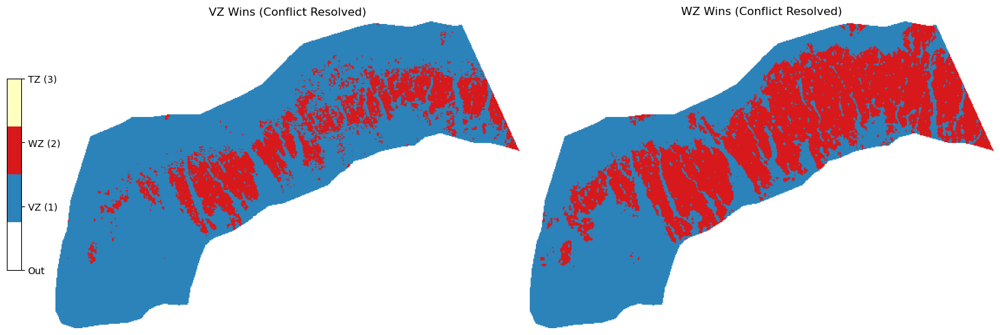

GeoTIFF saved: /Volumes/MaloneLab/Research/Whitezone/Result/Emulation/Final/CDthreshold06/CD_closest_GE/Subregion_2_transect/Region_0/Projected_LandCover_VZwins.tif


In [18]:
# Background and Rules

#Pixel size: 30 meters

#WZ expansion rate: 16.4 m/year 

#VZ expansion rate: 13.3 m/year

#Valid expansion only into Transition Zone (value == 3)

#VZ wins / WZ wins in overlapping areas

#Existing WZ and VZ are protected

# === Step 1: Read latest raster ===
folder = "/Volumes/MaloneLab/Research/Whitezone/Result/Emulation/Final/CDthreshold06/CD_closest_GE/Subregion_2_transect/Region_0"
tif_files = sorted([f for f in os.listdir(folder) if f.endswith('.tif')])
latest_file = os.path.join(folder, tif_files[-1])

with rasterio.open(latest_file) as src:
    base = src.read(1)
    profile = src.profile

# === Step 2: Parameters ===
pixel_size = 30  # meters
years = 25
WZ_rate = 16.4  # m/year
VZ_rate = 13.3  # m/year
WZ_buffer_px = int(round(WZ_rate * years / pixel_size))  # ≈ 27
VZ_buffer_px = int(round(VZ_rate * years / pixel_size))  # ≈ 22

# === Step 3: Create zone masks ===
WZ_mask = (base == 2)  # White Zone
VZ_mask = (base == 1)  # Vegetation Zone
TZ_mask = (base == 3)  # Transition Zone
valid_mask = TZ_mask.copy()  # Only TZ can be expanded into

# === CASE 1: Conflict resolved (VZ wins) ===
WZ_exp1 = binary_dilation(WZ_mask, iterations=WZ_buffer_px) & valid_mask
VZ_exp1 = binary_dilation(VZ_mask, iterations=VZ_buffer_px) & valid_mask
WZ_exp1[VZ_exp1] = False  # Conflict: VZ wins

projected1 = base.copy()
projected1[WZ_exp1] = 2
projected1[VZ_exp1] = 1

# === CASE 2: No conflict resolution — WZ can overwrite ===
WZ_exp2 = binary_dilation(WZ_mask, iterations=WZ_buffer_px) & valid_mask
VZ_exp2 = binary_dilation(VZ_mask, iterations=VZ_buffer_px) & valid_mask

projected2 = base.copy()
projected2[VZ_exp2] = 1
projected2[WZ_exp2] = 2  # WZ wins
VZ_exp1[WZ_exp1] = False  # Conflict: WZ wins

# === Step 4: Plot both results ===
cmap = ListedColormap(['white', '#2b83ba', '#d7191c', '#ffffbf'])  # 0=white, 1=blue, 2=red, 3=yellow

fig, axs = plt.subplots(1, 2, figsize=(14, 7))
titles = ["VZ Wins (Conflict Resolved)", "WZ Wins (Conflict Resolved)"]

for ax, img, title in zip(axs, [projected1, projected2], titles):
    im = ax.imshow(img, cmap=cmap, vmin=0, vmax=3)
    ax.set_title(title)
    ax.axis("off")

cbar_ax = fig.add_axes([-0.04, 0.3, 0.015, 0.4])  # [left, bottom, width, height]
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_ticks([0, 1, 2, 3])
cbar.set_ticklabels(["Out", "VZ (1)", "WZ (2)", "TZ (3)"])
cbar.ax.tick_params(labelsize=10)

plt.tight_layout()
plt.show()

# === Step 5: Save output GeoTIFF ===
output_file = os.path.join(folder, "Projected_LandCover_VZwins.tif")
with rasterio.open(output_file, 'w', **profile) as dst:
    dst.write(projected1.astype(rasterio.uint8), 1)

print(f"GeoTIFF saved: {output_file}")



/var/folders/yw/3l8t5xh50v33m6zjql7k1rzsvhfd38/T/ipykernel_59544/359060335.py:42: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0.05, 0, 1, 1])


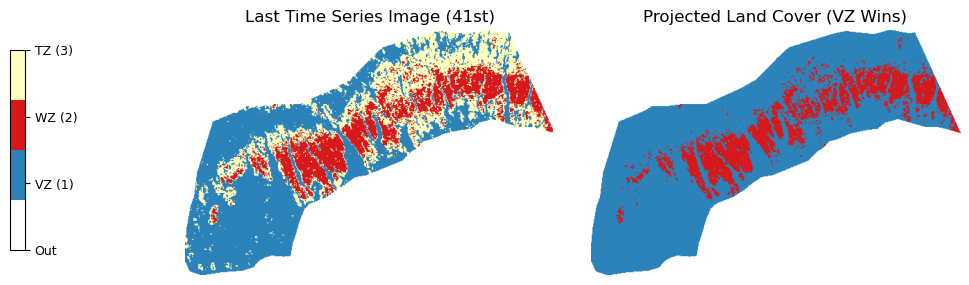

In [19]:
##### Comparison between 2024 and the VZ win scenario ####
import os
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Folder and files
folder = "/Volumes/MaloneLab/Research/Whitezone/Result/Emulation/Final/CDthreshold06/CD_closest_GE/Subregion_2_transect/Region_0"
tif_files = sorted([f for f in os.listdir(folder) if f.endswith('.tif')])

# Read last (41st) image
last_file = os.path.join(folder, tif_files[-1])
with rasterio.open(last_file) as src:
    last_img = src.read(1)

# Assume 'projected1' (VZ wins) already exists from your previous processing

# Define colormap for plotting
colors = ['white', '#2b83ba', '#d7191c', '#ffffbf']  # 0=out,1=VZ,2=WZ,3=TZ
cmap = ListedColormap(colors)

fig, axs = plt.subplots(1, 2, figsize=(10, 5), gridspec_kw={'wspace':0.1})

# Plot last time series image
axs[0].imshow(last_img, cmap=cmap, vmin=0, vmax=3)
axs[0].set_title("Last Time Series Image (41st)")
axs[0].axis("off")

# Plot projected land cover (VZ wins)
im = axs[1].imshow(projected1, cmap=cmap, vmin=0, vmax=3)
axs[1].set_title("Projected Land Cover (VZ Wins)")
axs[1].axis("off")

# Colorbar on the left outside
cbar_ax = fig.add_axes([-0.05, 0.3, 0.015, 0.4])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_ticks([0, 1, 2, 3])
cbar.set_ticklabels(["Out", "VZ (1)", "WZ (2)", "TZ (3)"])
cbar.ax.tick_params(labelsize=9)

plt.tight_layout(rect=[0.05, 0, 1, 1])
plt.show()


/var/folders/yw/3l8t5xh50v33m6zjql7k1rzsvhfd38/T/ipykernel_59544/1998502585.py:64: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0.05, 0, 1, 1])


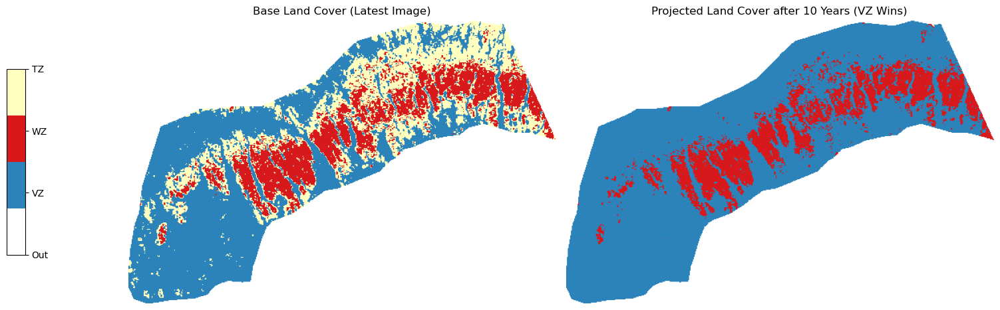

In [42]:
### 10 years expansion ####

# === Step 1: Read latest raster ===
folder = "/Volumes/MaloneLab/Research/Whitezone/Result/Emulation/Final/CDthreshold06/CD_closest_GE/Subregion_2_transect/Region_0"
tif_files = sorted([f for f in os.listdir(folder) if f.endswith('.tif')])
latest_file = os.path.join(folder, tif_files[-1])

with rasterio.open(latest_file) as src:
    base = src.read(1)
    profile = src.profile

# === Step 2: Create masks ===
WZ_mask = (base == 2)
VZ_mask = (base == 1)
TZ_mask = (base == 3)
valid_mask = TZ_mask.copy()  # expansion allowed only here

# === Step 3: Expansion parameters for 10 years ===
WZ_expansion_pixels = 6
VZ_expansion_pixels = 8

# Dilate current zones
WZ_exp = binary_dilation(WZ_mask, iterations=WZ_expansion_pixels) & valid_mask
VZ_exp = binary_dilation(VZ_mask, iterations=VZ_expansion_pixels) & valid_mask

# Conflict resolution: VZ wins, so remove overlapping expansions from WZ
WZ_exp[VZ_exp] = False

# Only newly expanded pixels (exclude existing)
WZ_new = WZ_exp & (~WZ_mask)
VZ_new = VZ_exp & (~VZ_mask)

# Update masks with new expansions
WZ_final = WZ_mask | WZ_new
VZ_final = VZ_mask | VZ_new

# === Step 4: Create final projected land cover ===
projected = base.copy()
projected[WZ_final] = 2
projected[VZ_final] = 1

# === Step 5: Plotting side-by-side ===
colors = ['white', '#2b83ba', '#d7191c', '#ffffbf']  # 0=Out, 1=VZ, 2=WZ, 3=TZ
cmap = ListedColormap(colors)

fig, axs = plt.subplots(1, 2, figsize=(14, 7))

# Plot base image (latest raster)
im0 = axs[0].imshow(base, cmap=cmap, vmin=0, vmax=3)
axs[0].set_title("Base Land Cover (Latest Image)")
axs[0].axis('off')

# Plot 10-year projection
im1 = axs[1].imshow(projected, cmap=cmap, vmin=0, vmax=3)
axs[1].set_title("Projected Land Cover after 10 Years (VZ Wins)")
axs[1].axis('off')

# Add colorbar on left outside of both plots
cbar_ax = fig.add_axes([-0.07, 0.3, 0.02, 0.4])  # Adjust position more left
cbar = fig.colorbar(im1, cax=cbar_ax, ticks=[0,1,2,3])
cbar.set_ticklabels(["Out", "VZ", "WZ", "TZ"])
cbar.ax.tick_params(labelsize=10)

plt.tight_layout(rect=[0.05, 0, 1, 1])
plt.show()


In [44]:
num_WZ_base = np.sum(base == 1)
num_WZ_projected = np.sum(projected == 1)

print(f"Number of WZ pixels (Base): {num_WZ_base}")
print(f"Number of WZ pixels (Projected 10-year): {num_WZ_projected}")

Number of WZ pixels (Base): 42986
Number of WZ pixels (Projected 10-year): 65903


/var/folders/yw/3l8t5xh50v33m6zjql7k1rzsvhfd38/T/ipykernel_59544/1147539989.py:64: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0.05, 0, 1, 1])


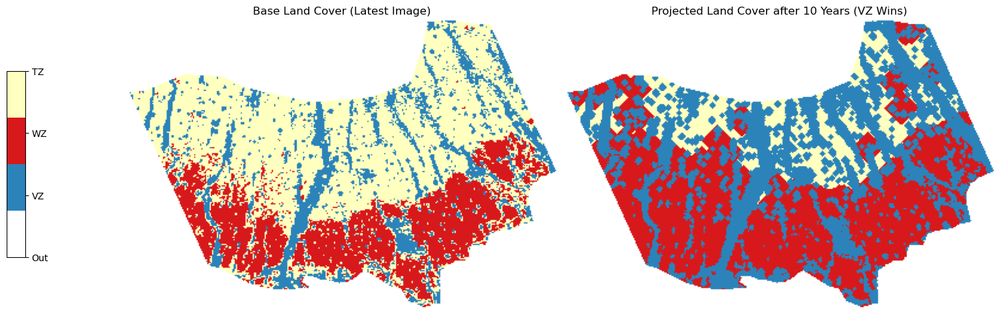

In [41]:
### 10 years expansion ####

# === Step 1: Read latest raster ===
folder = "/Volumes/MaloneLab/Research/Whitezone/Result/Emulation/Final/CDthreshold06/CD_closest_GE/Subregion_2_transect/Region_1"
tif_files = sorted([f for f in os.listdir(folder) if f.endswith('.tif')])
latest_file = os.path.join(folder, tif_files[-1])

with rasterio.open(latest_file) as src:
    base = src.read(1)
    profile = src.profile

# === Step 2: Create masks ===
WZ_mask = (base == 2)
VZ_mask = (base == 1)
TZ_mask = (base == 3)
valid_mask = TZ_mask.copy()  # expansion allowed only here

# === Step 3: Expansion parameters for 10 years ===
WZ_expansion_pixels = 13
VZ_expansion_pixels = 2

# Dilate current zones
WZ_exp = binary_dilation(WZ_mask, iterations=WZ_expansion_pixels) & valid_mask
VZ_exp = binary_dilation(VZ_mask, iterations=VZ_expansion_pixels) & valid_mask

# Conflict resolution: VZ wins, so remove overlapping expansions from WZ
WZ_exp[VZ_exp] = False

# Only newly expanded pixels (exclude existing)
WZ_new = WZ_exp & (~WZ_mask)
VZ_new = VZ_exp & (~VZ_mask)

# Update masks with new expansions
WZ_final = WZ_mask | WZ_new
VZ_final = VZ_mask | VZ_new

# === Step 4: Create final projected land cover ===
projected = base.copy()
projected[WZ_final] = 2
projected[VZ_final] = 1

# === Step 5: Plotting side-by-side ===
colors = ['white', '#2b83ba', '#d7191c', '#ffffbf']  # 0=Out, 1=VZ, 2=WZ, 3=TZ
cmap = ListedColormap(colors)

fig, axs = plt.subplots(1, 2, figsize=(14, 7))

# Plot base image (latest raster)
im0 = axs[0].imshow(base, cmap=cmap, vmin=0, vmax=3)
axs[0].set_title("Base Land Cover (Latest Image)")
axs[0].axis('off')

# Plot 10-year projection
im1 = axs[1].imshow(projected, cmap=cmap, vmin=0, vmax=3)
axs[1].set_title("Projected Land Cover after 10 Years (VZ Wins)")
axs[1].axis('off')

# Add colorbar on left outside of both plots
cbar_ax = fig.add_axes([-0.07, 0.3, 0.02, 0.4])  # Adjust position more left
cbar = fig.colorbar(im1, cax=cbar_ax, ticks=[0,1,2,3])
cbar.set_ticklabels(["Out", "VZ", "WZ", "TZ"])
cbar.ax.tick_params(labelsize=10)

plt.tight_layout(rect=[0.05, 0, 1, 1])
plt.show()


/var/folders/yw/3l8t5xh50v33m6zjql7k1rzsvhfd38/T/ipykernel_59544/3374942494.py:65: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0.05, 0, 1, 1])


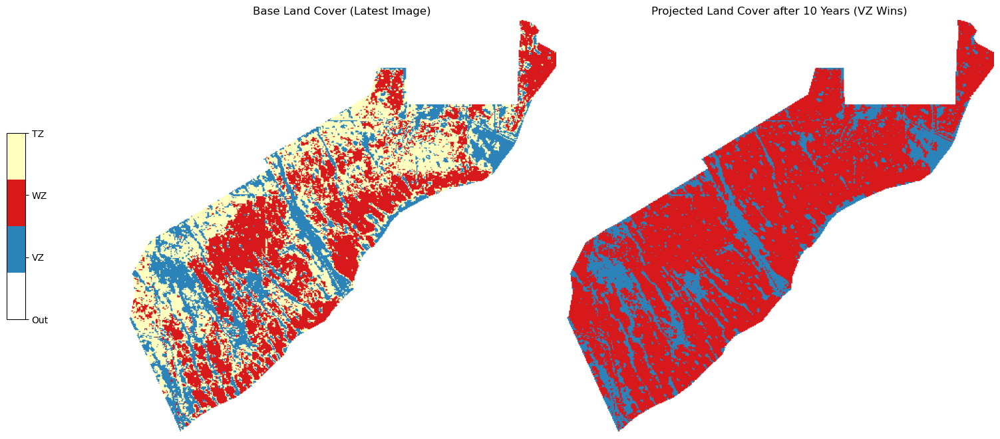

In [50]:
### 10 years expansion ####

# === Step 1: Read latest raster ===
folder = "/Volumes/MaloneLab/Research/Whitezone/Result/Emulation/Final/CDthreshold06/CD_closest_GE/Subregion_2_transect/Region_2"
tif_files = sorted([f for f in os.listdir(folder) if f.endswith('.tif')])
latest_file = os.path.join(folder, tif_files[-1])

with rasterio.open(latest_file) as src:
    base = src.read(1)
    profile = src.profile

# === Step 2: Create masks ===
WZ_mask = (base == 2)
VZ_mask = (base == 1)
TZ_mask = (base == 3)
valid_mask = TZ_mask.copy()  # expansion allowed only here

# === Step 3: Expansion parameters for 10 years ===
WZ_expansion_pixels = 23
VZ_expansion_pixels = 13

# Dilate current zones
WZ_exp = binary_dilation(WZ_mask, iterations=WZ_expansion_pixels) & valid_mask
VZ_exp = binary_dilation(VZ_mask, iterations=VZ_expansion_pixels) & valid_mask

# Conflict resolution: VZ wins, so remove overlapping expansions from WZ
#WZ_exp[VZ_exp] = False

# Only newly expanded pixels (exclude existing)
WZ_new = WZ_exp & (~WZ_mask)
VZ_new = VZ_exp & (~VZ_mask)

# Update masks with new expansions
WZ_final = WZ_mask | WZ_new
VZ_final = VZ_mask | VZ_new

# === Step 4: Create final projected land cover ===
projected = base.copy()

projected[VZ_final] = 1
projected[WZ_final] = 2

# === Step 5: Plotting side-by-side ===
colors = ['white', '#2b83ba', '#d7191c', '#ffffbf']  # 0=Out, 1=VZ, 2=WZ, 3=TZ
cmap = ListedColormap(colors)

fig, axs = plt.subplots(1, 2, figsize=(14, 7))

# Plot base image (latest raster)
im0 = axs[0].imshow(base, cmap=cmap, vmin=0, vmax=3)
axs[0].set_title("Base Land Cover (Latest Image)")
axs[0].axis('off')

# Plot 10-year projection
im1 = axs[1].imshow(projected, cmap=cmap, vmin=0, vmax=3)
axs[1].set_title("Projected Land Cover after 10 Years (VZ Wins)")
axs[1].axis('off')

# Add colorbar on left outside of both plots
cbar_ax = fig.add_axes([-0.07, 0.3, 0.02, 0.4])  # Adjust position more left
cbar = fig.colorbar(im1, cax=cbar_ax, ticks=[0,1,2,3])
cbar.set_ticklabels(["Out", "VZ", "WZ", "TZ"])
cbar.ax.tick_params(labelsize=10)

plt.tight_layout(rect=[0.05, 0, 1, 1])
plt.show()


In [49]:
num_WZ_base = np.sum(base == 2)
num_WZ_projected = np.sum(projected == 2)

print(f"Number of WZ pixels (Base): {num_WZ_base}")
print(f"Number of WZ pixels (Projected 10-year): {num_WZ_projected}")

Number of WZ pixels (Base): 26289
Number of WZ pixels (Projected 10-year): 26328


Year 1: WZ grew by 193, VZ grew by 253
Year 2: WZ grew by 193, VZ grew by 253
Year 3: WZ grew by 193, VZ grew by 253
Year 4: WZ grew by 193, VZ grew by 253
Year 5: WZ grew by 193, VZ grew by 253
Year 6: WZ grew by 193, VZ grew by 253
Year 7: WZ grew by 193, VZ grew by 253
Year 8: WZ grew by 193, VZ grew by 253
Year 9: WZ grew by 193, VZ grew by 253
Year 10: WZ grew by 193, VZ grew by 253
Year 11: WZ grew by 193, VZ grew by 253
Year 12: WZ grew by 193, VZ grew by 253
Year 13: WZ grew by 193, VZ grew by 253
Year 14: WZ grew by 193, VZ grew by 253
Year 15: WZ grew by 193, VZ grew by 253
Year 16: WZ grew by 193, VZ grew by 253
Year 17: WZ grew by 193, VZ grew by 253
Year 18: WZ grew by 193, VZ grew by 253
Year 19: WZ grew by 193, VZ grew by 253
Year 20: WZ grew by 193, VZ grew by 253
Year 21: WZ grew by 193, VZ grew by 253
Year 22: WZ grew by 193, VZ grew by 253
Year 23: WZ grew by 193, VZ grew by 253
Year 24: WZ grew by 193, VZ grew by 253
Year 25: WZ grew by 193, VZ grew by 253


/var/folders/yw/3l8t5xh50v33m6zjql7k1rzsvhfd38/T/ipykernel_59544/598864429.py:72: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])


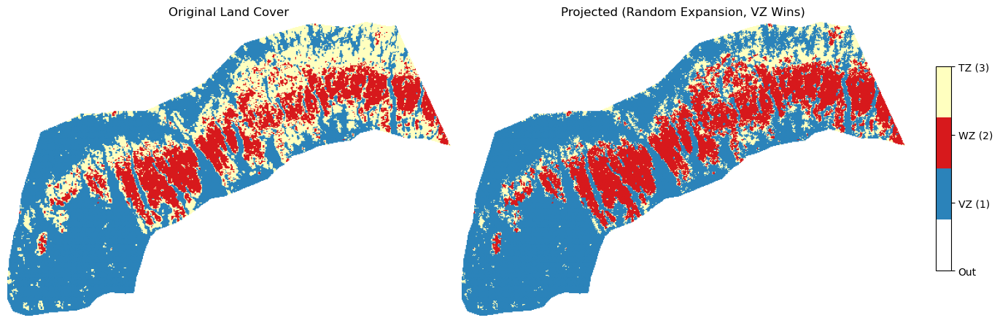

In [81]:
## Randomly dropped the limited amount of pixels to adjacent areas 

# === Step 1: Load latest raster ===
folder = "/Volumes/MaloneLab/Research/Whitezone/Result/Emulation/Final/CDthreshold06/CD_closest_GE/Subregion_2_transect/Region_0"
tif_files = sorted([f for f in os.listdir(folder) if f.endswith('.tif')])
latest_file = os.path.join(folder, tif_files[-1])

with rasterio.open(latest_file) as src:
    base = src.read(1)
    profile = src.profile

# === Step 2: Setup ===
years = 25
WZ_per_year = 193  # pixels/year
VZ_per_year = 253  # pixels/year

# Make a working copy of the landcover
landcover = base.copy()

# === Step 3: Simulate yearly expansion ===
for year in range(years):
    # Masks
    WZ_mask = (landcover == 2)
    VZ_mask = (landcover == 1)
    TZ_mask = (landcover == 3)

    # Find candidate edge pixels (1-pixel dilated edge)
    WZ_edge = binary_dilation(WZ_mask) & TZ_mask
    VZ_edge = binary_dilation(VZ_mask) & TZ_mask

    # Conflict resolution: if a pixel is in both edge zones, assign it to VZ
    conflict = WZ_edge & VZ_edge
    WZ_edge[conflict] = False  # remove conflict from WZ
    # VZ keeps the conflict pixels

    # Randomly pick from candidate edge pixels
    wz_candidates = list(zip(*np.where(WZ_edge)))
    vz_candidates = list(zip(*np.where(VZ_edge)))

    wz_new = random.sample(wz_candidates, min(WZ_per_year, len(wz_candidates)))
    vz_new = random.sample(vz_candidates, min(VZ_per_year, len(vz_candidates)))

    for r, c in wz_new:
        landcover[r, c] = 2
    for r, c in vz_new:
        landcover[r, c] = 1

    print(f"Year {year+1}: WZ grew by {len(wz_new)}, VZ grew by {len(vz_new)}")

# === Step 4: Plot original vs projected ===
cmap = ListedColormap(['white', '#2b83ba', '#d7191c', '#ffffbf'])  # 0=white, 1=blue, 2=red, 3=yellow

fig, axs = plt.subplots(1, 2, figsize=(14, 7))

# Plot original
axs[0].imshow(base, cmap=cmap, vmin=0, vmax=3)
axs[0].set_title("Original Land Cover")
axs[0].axis("off")

# Plot projected
axs[1].imshow(landcover, cmap=cmap, vmin=0, vmax=3)
axs[1].set_title("Projected (Random Expansion, VZ Wins)")
axs[1].axis("off")

# Shared colorbar
cbar_ax = fig.add_axes([0.92, 0.3, 0.015, 0.4])
cbar = fig.colorbar(axs[1].images[0], cax=cbar_ax)
cbar.set_ticks([0, 1, 2, 3])
cbar.set_ticklabels(["Out", "VZ (1)", "WZ (2)", "TZ (3)"])
cbar.ax.tick_params(labelsize=10)

plt.tight_layout(rect=[0, 0, 0.9, 1])
plt.show()


Year 1: WZ grew by 198, VZ grew by 33
Year 2: WZ grew by 198, VZ grew by 33
Year 3: WZ grew by 198, VZ grew by 33
Year 4: WZ grew by 198, VZ grew by 33
Year 5: WZ grew by 198, VZ grew by 33
Year 6: WZ grew by 198, VZ grew by 33
Year 7: WZ grew by 198, VZ grew by 33
Year 8: WZ grew by 198, VZ grew by 33
Year 9: WZ grew by 198, VZ grew by 33
Year 10: WZ grew by 198, VZ grew by 33
Year 11: WZ grew by 198, VZ grew by 33
Year 12: WZ grew by 198, VZ grew by 33
Year 13: WZ grew by 198, VZ grew by 33
Year 14: WZ grew by 198, VZ grew by 33
Year 15: WZ grew by 198, VZ grew by 33
Year 16: WZ grew by 198, VZ grew by 33
Year 17: WZ grew by 198, VZ grew by 33
Year 18: WZ grew by 198, VZ grew by 33
Year 19: WZ grew by 198, VZ grew by 33
Year 20: WZ grew by 198, VZ grew by 33
Year 21: WZ grew by 198, VZ grew by 33
Year 22: WZ grew by 198, VZ grew by 33
Year 23: WZ grew by 198, VZ grew by 33
Year 24: WZ grew by 198, VZ grew by 33
Year 25: WZ grew by 198, VZ grew by 33


/var/folders/yw/3l8t5xh50v33m6zjql7k1rzsvhfd38/T/ipykernel_59544/3356619430.py:70: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])


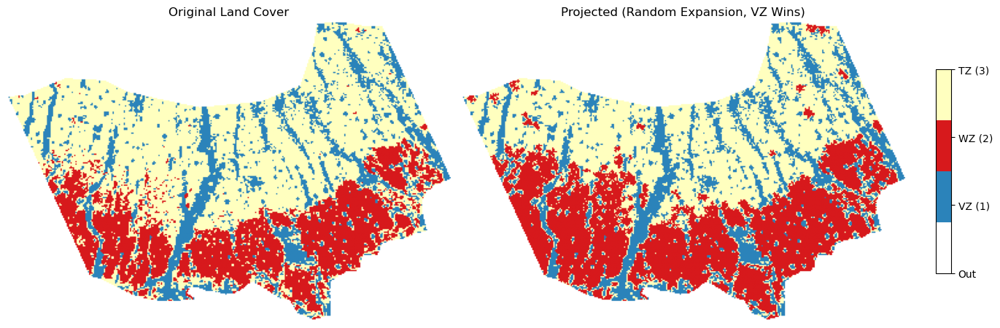

In [66]:
# === Step 1: Load latest raster ===
folder = "/Volumes/MaloneLab/Research/Whitezone/Result/Emulation/Final/CDthreshold06/CD_closest_GE/Subregion_2_transect/Region_1"
tif_files = sorted([f for f in os.listdir(folder) if f.endswith('.tif')])
latest_file = os.path.join(folder, tif_files[-1])

with rasterio.open(latest_file) as src:
    base = src.read(1)
    profile = src.profile

# === Step 2: Setup ===
years = 25
WZ_per_year = 198  # pixels/year
VZ_per_year = 33  # pixels/year

# Make a working copy of the landcover
landcover = base.copy()

# === Step 3: Simulate yearly expansion ===
for year in range(years):
    # Masks
    WZ_mask = (landcover == 2)
    VZ_mask = (landcover == 1)
    TZ_mask = (landcover == 3)

    # Find candidate edge pixels (1-pixel dilated edge)
    WZ_edge = binary_dilation(WZ_mask) & TZ_mask
    VZ_edge = binary_dilation(VZ_mask) & TZ_mask

    # Conflict resolution: if a pixel is in both edge zones, assign it to VZ
    conflict = WZ_edge & VZ_edge
    WZ_edge[conflict] = False  # remove conflict from WZ
    # VZ keeps the conflict pixels

    # Randomly pick from candidate edge pixels
    wz_candidates = list(zip(*np.where(WZ_edge)))
    vz_candidates = list(zip(*np.where(VZ_edge)))

    wz_new = random.sample(wz_candidates, min(WZ_per_year, len(wz_candidates)))
    vz_new = random.sample(vz_candidates, min(VZ_per_year, len(vz_candidates)))

    for r, c in wz_new:
        landcover[r, c] = 2
    for r, c in vz_new:
        landcover[r, c] = 1

    print(f"Year {year+1}: WZ grew by {len(wz_new)}, VZ grew by {len(vz_new)}")

# === Step 4: Plot original vs projected ===
cmap = ListedColormap(['white', '#2b83ba', '#d7191c', '#ffffbf'])  # 0=white, 1=blue, 2=red, 3=yellow

fig, axs = plt.subplots(1, 2, figsize=(14, 7))

# Plot original
axs[0].imshow(base, cmap=cmap, vmin=0, vmax=3)
axs[0].set_title("Original Land Cover")
axs[0].axis("off")

# Plot projected
axs[1].imshow(landcover, cmap=cmap, vmin=0, vmax=3)
axs[1].set_title("Projected (Random Expansion, VZ Wins)")
axs[1].axis("off")

# Shared colorbar
cbar_ax = fig.add_axes([0.92, 0.3, 0.015, 0.4])
cbar = fig.colorbar(axs[1].images[0], cax=cbar_ax)
cbar.set_ticks([0, 1, 2, 3])
cbar.set_ticklabels(["Out", "VZ (1)", "WZ (2)", "TZ (3)"])
cbar.ax.tick_params(labelsize=10)

plt.tight_layout(rect=[0, 0, 0.9, 1])
plt.show()


Year 1: WZ grew by 228, VZ grew by 131
Year 2: WZ grew by 228, VZ grew by 131
Year 3: WZ grew by 228, VZ grew by 131
Year 4: WZ grew by 228, VZ grew by 131
Year 5: WZ grew by 228, VZ grew by 131
Year 6: WZ grew by 228, VZ grew by 131
Year 7: WZ grew by 228, VZ grew by 131
Year 8: WZ grew by 228, VZ grew by 131
Year 9: WZ grew by 228, VZ grew by 131
Year 10: WZ grew by 228, VZ grew by 131
Year 11: WZ grew by 228, VZ grew by 131
Year 12: WZ grew by 228, VZ grew by 131
Year 13: WZ grew by 228, VZ grew by 131
Year 14: WZ grew by 228, VZ grew by 131
Year 15: WZ grew by 228, VZ grew by 131
Year 16: WZ grew by 228, VZ grew by 131
Year 17: WZ grew by 228, VZ grew by 131
Year 18: WZ grew by 228, VZ grew by 131
Year 19: WZ grew by 228, VZ grew by 131
Year 20: WZ grew by 228, VZ grew by 131
Year 21: WZ grew by 228, VZ grew by 131
Year 22: WZ grew by 228, VZ grew by 131
Year 23: WZ grew by 228, VZ grew by 131
Year 24: WZ grew by 228, VZ grew by 131
Year 25: WZ grew by 228, VZ grew by 131


/var/folders/yw/3l8t5xh50v33m6zjql7k1rzsvhfd38/T/ipykernel_59544/1071069475.py:70: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])


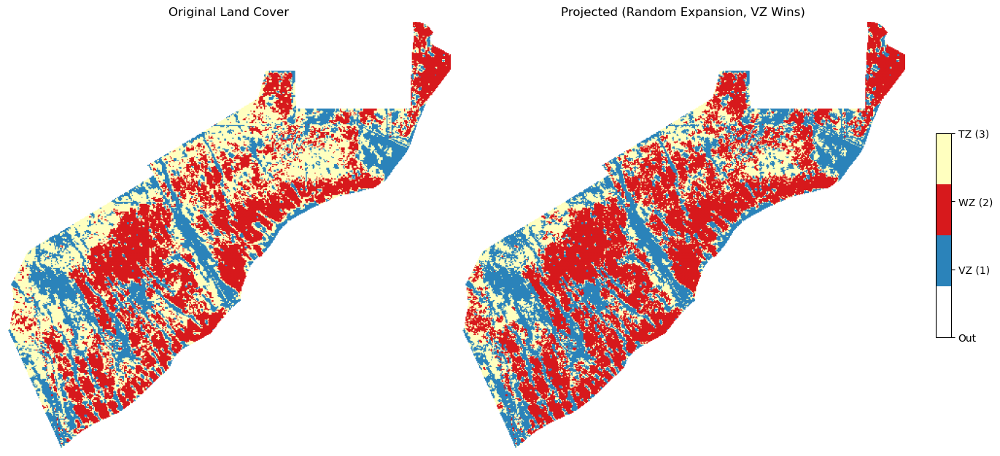

In [75]:
# === Step 1: Load latest raster ===
folder = "/Volumes/MaloneLab/Research/Whitezone/Result/Emulation/Final/CDthreshold06/CD_closest_GE/Subregion_2_transect/Region_2"
tif_files = sorted([f for f in os.listdir(folder) if f.endswith('.tif')])
latest_file = os.path.join(folder, tif_files[-1])

with rasterio.open(latest_file) as src:
    base = src.read(1)
    profile = src.profile

# === Step 2: Setup ===
years = 25
WZ_per_year = 228  # pixels/year
VZ_per_year = 131  # pixels/year

# Make a working copy of the landcover
landcover = base.copy()

# === Step 3: Simulate yearly expansion ===
for year in range(years):
    # Masks
    WZ_mask = (landcover == 2)
    VZ_mask = (landcover == 1)
    TZ_mask = (landcover == 3)

    # Find candidate edge pixels (1-pixel dilated edge)
    WZ_edge = binary_dilation(WZ_mask) & TZ_mask
    VZ_edge = binary_dilation(VZ_mask) & TZ_mask

    # Conflict resolution: if a pixel is in both edge zones, assign it to VZ
    conflict = WZ_edge & VZ_edge
    WZ_edge[conflict] = False  # remove conflict from WZ
    # VZ keeps the conflict pixels

    # Randomly pick from candidate edge pixels
    wz_candidates = list(zip(*np.where(WZ_edge)))
    vz_candidates = list(zip(*np.where(VZ_edge)))

    wz_new = random.sample(wz_candidates, min(WZ_per_year, len(wz_candidates)))
    vz_new = random.sample(vz_candidates, min(VZ_per_year, len(vz_candidates)))

    for r, c in wz_new:
        landcover[r, c] = 2
    for r, c in vz_new:
        landcover[r, c] = 1

    print(f"Year {year+1}: WZ grew by {len(wz_new)}, VZ grew by {len(vz_new)}")

# === Step 4: Plot original vs projected ===
cmap = ListedColormap(['white', '#2b83ba', '#d7191c', '#ffffbf'])  # 0=white, 1=blue, 2=red, 3=yellow

fig, axs = plt.subplots(1, 2, figsize=(14, 7))

# Plot original
axs[0].imshow(base, cmap=cmap, vmin=0, vmax=3)
axs[0].set_title("Original Land Cover")
axs[0].axis("off")

# Plot projected
axs[1].imshow(landcover, cmap=cmap, vmin=0, vmax=3)
axs[1].set_title("Projected (Random Expansion, VZ Wins)")
axs[1].axis("off")

# Shared colorbar
cbar_ax = fig.add_axes([0.92, 0.3, 0.015, 0.4])
cbar = fig.colorbar(axs[1].images[0], cax=cbar_ax)
cbar.set_ticks([0, 1, 2, 3])
cbar.set_ticklabels(["Out", "VZ (1)", "WZ (2)", "TZ (3)"])
cbar.ax.tick_params(labelsize=10)

plt.tight_layout(rect=[0, 0, 0.9, 1])
plt.show()


Year 1/25: WZ→TZ=190, WZ→VZ=3 | VZ→TZ=249, VZ→WZ=4
Year 2/25: WZ→TZ=190, WZ→VZ=3 | VZ→TZ=249, VZ→WZ=4
Year 3/25: WZ→TZ=190, WZ→VZ=3 | VZ→TZ=249, VZ→WZ=4
Year 4/25: WZ→TZ=190, WZ→VZ=3 | VZ→TZ=249, VZ→WZ=4
Year 5/25: WZ→TZ=190, WZ→VZ=3 | VZ→TZ=249, VZ→WZ=4
Year 6/25: WZ→TZ=190, WZ→VZ=3 | VZ→TZ=249, VZ→WZ=4
Year 7/25: WZ→TZ=190, WZ→VZ=3 | VZ→TZ=249, VZ→WZ=4
Year 8/25: WZ→TZ=190, WZ→VZ=3 | VZ→TZ=249, VZ→WZ=4
Year 9/25: WZ→TZ=190, WZ→VZ=3 | VZ→TZ=249, VZ→WZ=4
Year 10/25: WZ→TZ=190, WZ→VZ=3 | VZ→TZ=249, VZ→WZ=4
Year 11/25: WZ→TZ=190, WZ→VZ=3 | VZ→TZ=249, VZ→WZ=4
Year 12/25: WZ→TZ=190, WZ→VZ=3 | VZ→TZ=249, VZ→WZ=4
Year 13/25: WZ→TZ=190, WZ→VZ=3 | VZ→TZ=249, VZ→WZ=4
Year 14/25: WZ→TZ=190, WZ→VZ=3 | VZ→TZ=249, VZ→WZ=4
Year 15/25: WZ→TZ=190, WZ→VZ=3 | VZ→TZ=249, VZ→WZ=4
Year 16/25: WZ→TZ=190, WZ→VZ=3 | VZ→TZ=249, VZ→WZ=4
Year 17/25: WZ→TZ=190, WZ→VZ=3 | VZ→TZ=249, VZ→WZ=4
Year 18/25: WZ→TZ=190, WZ→VZ=3 | VZ→TZ=249, VZ→WZ=4
Year 19/25: WZ→TZ=190, WZ→VZ=3 | VZ→TZ=249, VZ→WZ=4
Year 20/25: WZ→TZ=190

/var/folders/yw/3l8t5xh50v33m6zjql7k1rzsvhfd38/T/ipykernel_59544/1033523853.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])


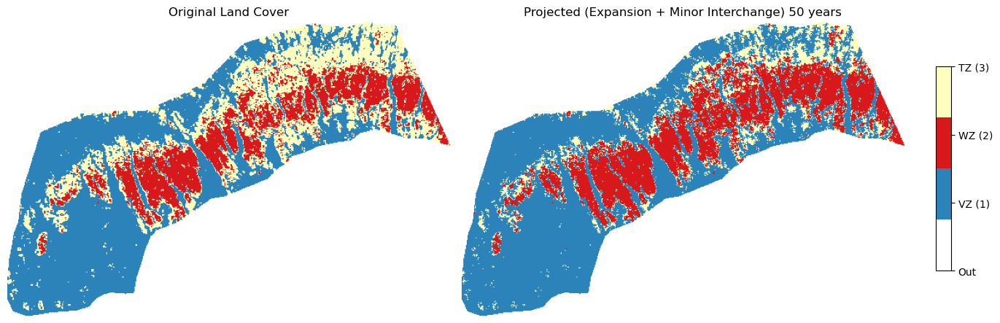